In [74]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:


df = pd.read_csv(
    "25001.txt",
    sep=r"\s+",
    skiprows=19,
    names=["FECHA", "PRECIP", "EVAP", "TMAX", "TMIN"],
    encoding="latin1",
    na_values=["Nulo"]
)


df.head()

,FECHA,PRECIP,EVAP,TMAX,TMIN
0,01/01/1961,0.0,NaN,25.0,13.0
1,02/01/1961,0.0,NaN,27.5,14.0
2,03/01/1961,0.0,NaN,31.0,11.0
3,04/01/1961,0.0,NaN,32.0,13.0
4,05/01/1961,0.0,NaN,29.0,14.0


In [ ]:

df.describe()

,PRECIP,EVAP,TMAX,TMIN
count,19534.000000,19302.000000,19569.000000,19568.000000
mean,2.217452,4.882157,34.468808,16.657420
std,9.015782,2.279340,3.430054,6.248605
min,0.000000,0.000000,18.000000,-2.500000
25%,0.000000,3.200000,32.500000,11.000000
50%,0.000000,4.500000,35.000000,16.500000
75%,0.000000,6.500000,37.000000,23.000000
max,217.400000,15.600000,45.500000,29.000000


In [ ]:

df.shape

(19575, 5)

In [ ]:

df.tail()

,FECHA,PRECIP,EVAP,TMAX,TMIN
19570,28/07/2018,9.8,3.7,37.0,23.5
19571,29/07/2018,6.0,3.3,35.0,20.0
19572,30/07/2018,48.0,6.0,36.0,22.0
19573,31/07/2018,2.0,3.7,34.0,22.0
19574,--------------------------------------,NaN,NaN,NaN,NaN


In [ ]:

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19575 entries, 0 to 19574
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   FECHA   19575 non-null  str    
 1   PRECIP  19534 non-null  float64
 2   EVAP    19302 non-null  float64
 3   TMAX    19569 non-null  float64
 4   TMIN    19568 non-null  float64
dtypes: float64(4), str(1)
memory usage: 764.8 KB


In [ ]:

df.describe()

,PRECIP,EVAP,TMAX,TMIN
count,19534.000000,19302.000000,19569.000000,19568.000000
mean,2.217452,4.882157,34.468808,16.657420
std,9.015782,2.279340,3.430054,6.248605
min,0.000000,0.000000,18.000000,-2.500000
25%,0.000000,3.200000,32.500000,11.000000
50%,0.000000,4.500000,35.000000,16.500000
75%,0.000000,6.500000,37.000000,23.000000
max,217.400000,15.600000,45.500000,29.000000


In [ ]:

mediciones = df[["PRECIP", "EVAP", "TMAX", "TMIN"]]
print("Media:")
print(mediciones.mean())
print("\nMediana:")
print(mediciones.median())
print("\nModa:")
print(mediciones.mode().iloc[0])
print("\nDesviación estándar:")
print(mediciones.std())
print("\nVarianza:")
print(mediciones.var())
print("\nRango:")
print(mediciones.max() - mediciones.min())

Media:
PRECIP     2.217452
EVAP       4.882157
TMAX      34.468808
TMIN      16.657420
dtype: float64

Mediana:
PRECIP     0.0
EVAP       4.5
TMAX      35.0
TMIN      16.5
dtype: float64

Moda:
PRECIP     0.0
EVAP       3.0
TMAX      35.0
TMIN      23.0
Name: 0, dtype: float64

Desviación estándar:
PRECIP    9.015782
EVAP      2.279340
TMAX      3.430054
TMIN      6.248605
dtype: float64

Varianza:
PRECIP    81.284328
EVAP       5.195392
TMAX      11.765268
TMIN      39.045069
dtype: float64

Rango:
PRECIP    217.4
EVAP       15.6
TMAX       27.5
TMIN       31.5
dtype: float64


In [ ]:

print("Valores faltantes por columna:")
print(df.isnull().sum())

Valores faltantes por columna:
FECHA       0
PRECIP     41
EVAP      273
TMAX        6
TMIN        7
dtype: int64


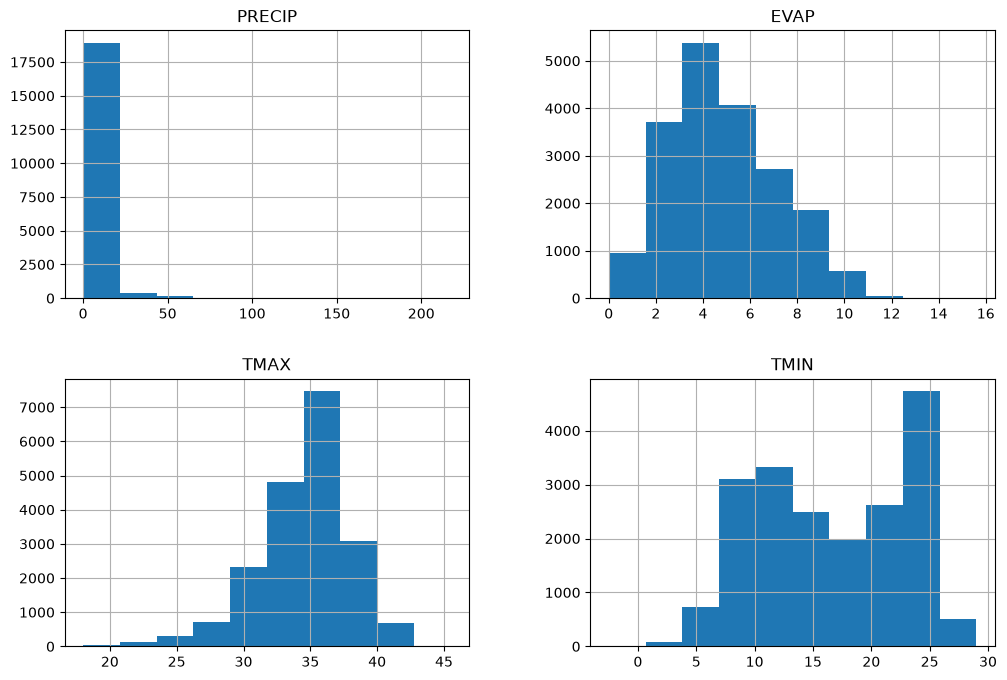

In [ ]:

df[["PRECIP", "EVAP", "TMAX", "TMIN"]].hist(figsize=(12, 8))

plt.show()

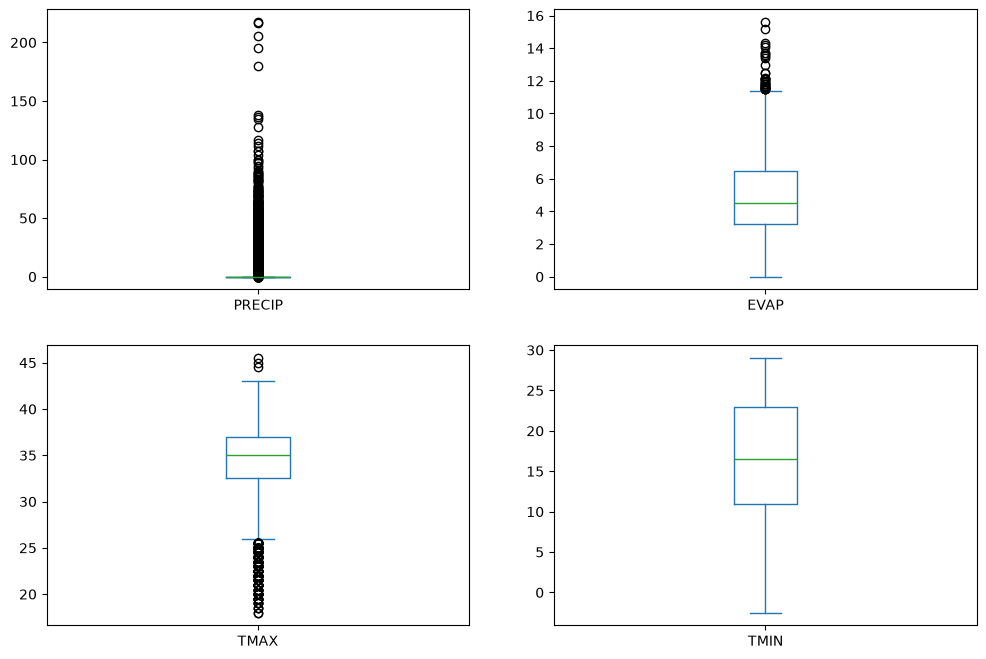

In [ ]:

df[["PRECIP", "EVAP", "TMAX", "TMIN"]].plot(
    kind="box",
    subplots=True,
    layout=(2, 2),
    figsize=(12, 8)
)


plt.show()

In [ ]:

print("Asimetría de las variables:")
print(df[["PRECIP", "EVAP", "TMAX", "TMIN"]].skew())

Asimetría de las variables:
PRECIP    7.982828
EVAP      0.444290
TMAX     -0.823858
TMIN     -0.112764
dtype: float64


In [ ]:

correlacion = df[["PRECIP", "EVAP", "TMAX", "TMIN"]].corr()


print(correlacion)

          PRECIP      EVAP      TMAX      TMIN
PRECIP  1.000000 -0.070830 -0.061332  0.236169
EVAP   -0.070830  1.000000  0.637680  0.141053
TMAX   -0.061332  0.637680  1.000000  0.398539
TMIN    0.236169  0.141053  0.398539  1.000000


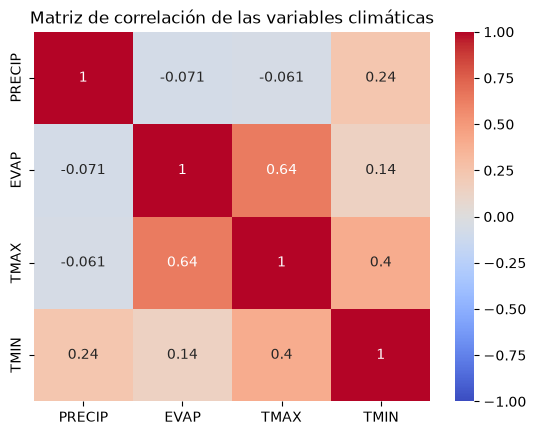

In [ ]:

sns.heatmap(correlacion, annot=True, cmap="coolwarm", vmin=-1, vmax=1)


plt.title("Matriz de correlación de las variables climáticas")


plt.show()

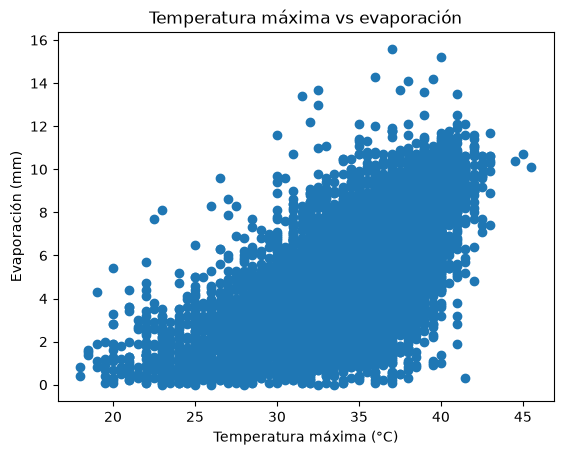

In [ ]:

plt.scatter(df["TMAX"], df["EVAP"])


plt.xlabel("Temperatura máxima (°C)")
plt.ylabel("Evaporación (mm)")


plt.title("Temperatura máxima vs evaporación")


plt.show()

In [ ]:

nulos = df.isnull().sum()


porcentaje = df.isnull().mean() * 100


resumen_nulos = pd.DataFrame({
    "Valores faltantes": nulos,
    "Porcentaje (%)": porcentaje
})


display(resumen_nulos.round(2))

,Valores faltantes,Porcentaje (%)
FECHA,0,0.00
PRECIP,41,0.21
EVAP,273,1.39
TMAX,6,0.03
TMIN,7,0.04


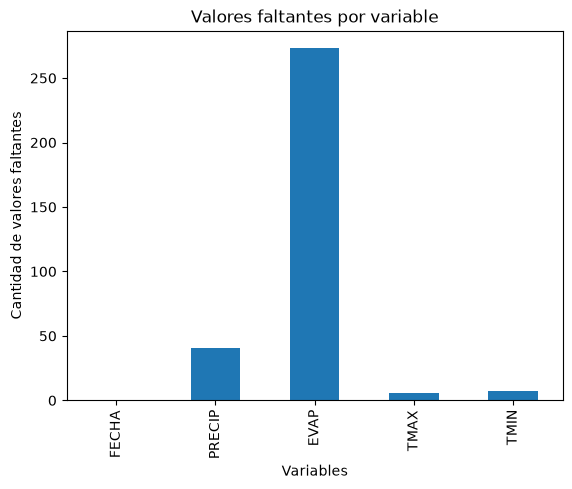

In [ ]:

nulos.plot(kind="bar")


plt.title("Valores faltantes por variable")
plt.xlabel("Variables")
plt.ylabel("Cantidad de valores faltantes")


plt.show()

In [ ]:
#Análisis y tratamiento de los datos faltantes
#se utilizará la media aritmética para rellenar los valores faltantes de las variables numéricas. 
#Este método consiste en calcular el promedio de los datos disponibles de cada columna y utilizarlo para sustituir sus valores faltantes.
#De esta manera, se conservarán los registros del conjunto de datos y se podrá continuar con el análisis estadístico y las gráficas.


nulos = df.isnull().sum()


porcentaje = df.isnull().mean() * 100


resumen_nulos = pd.DataFrame({
    "Datos faltantes": nulos,
    "Porcentaje (%)": porcentaje
})


display(resumen_nulos.round(2))


print("Total de datos faltantes:", df.isnull().sum().sum())


,Datos faltantes,Porcentaje (%)
FECHA,0,0.00
PRECIP,41,0.21
EVAP,273,1.39
TMAX,6,0.03
TMIN,7,0.04


Total de datos faltantes: 327


In [ ]:

columnas = ["PRECIP", "EVAP", "TMAX", "TMIN"]


for columna in columnas:
    df[columna] = df[columna].fillna(df[columna].mean())


print("Datos faltantes después de rellenar:")
print(df[columnas].isnull().sum())

print("\nTotal de datos faltantes restantes:", df[columnas].isnull().sum().sum())

Datos faltantes después de rellenar:
PRECIP    0
EVAP      0
TMAX      0
TMIN      0
dtype: int64

Total de datos faltantes restantes: 0


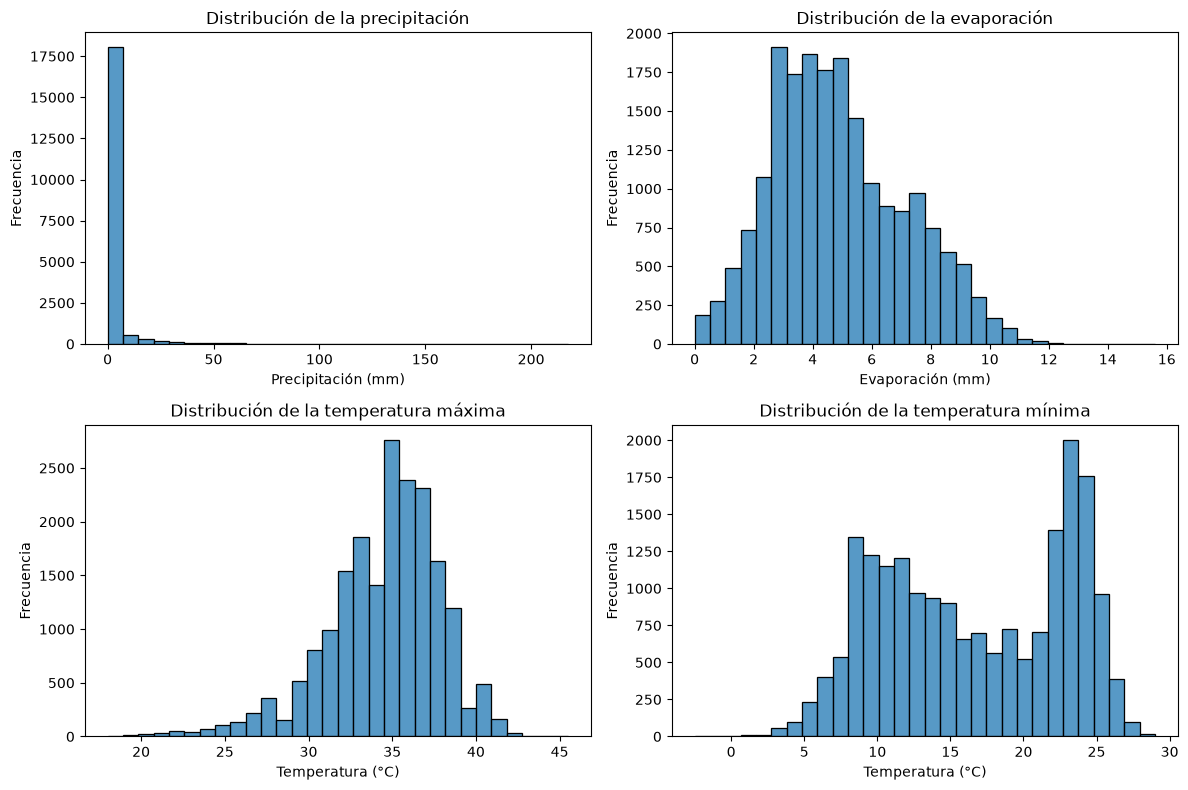

In [ ]:

plt.figure(figsize=(12, 8))


plt.subplot(2, 2, 1)
sns.histplot(data=df, x="PRECIP", bins=30)
plt.title("Distribución de la precipitación")
plt.xlabel("Precipitación (mm)")
plt.ylabel("Frecuencia")


plt.subplot(2, 2, 2)
sns.histplot(data=df, x="EVAP", bins=30)
plt.title("Distribución de la evaporación")
plt.xlabel("Evaporación (mm)")
plt.ylabel("Frecuencia")


plt.subplot(2, 2, 3)
sns.histplot(data=df, x="TMAX", bins=30)
plt.title("Distribución de la temperatura máxima")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Frecuencia")


plt.subplot(2, 2, 4)
sns.histplot(data=df, x="TMIN", bins=30)
plt.title("Distribución de la temperatura mínima")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Frecuencia")


plt.tight_layout()


plt.show()

### Conclusión de los histogramas

Los histogramas muestran que la precipitación presenta una fuerte asimetría positiva, mientras que la evaporación tiene una distribución más concentrada. La temperatura máxima presenta una ligera asimetría negativa y la temperatura mínima muestra dos concentraciones principales de valores. Estas diferencias permiten conocer el comportamiento de las variables y continuar con la identificación de posibles valores atípicos.

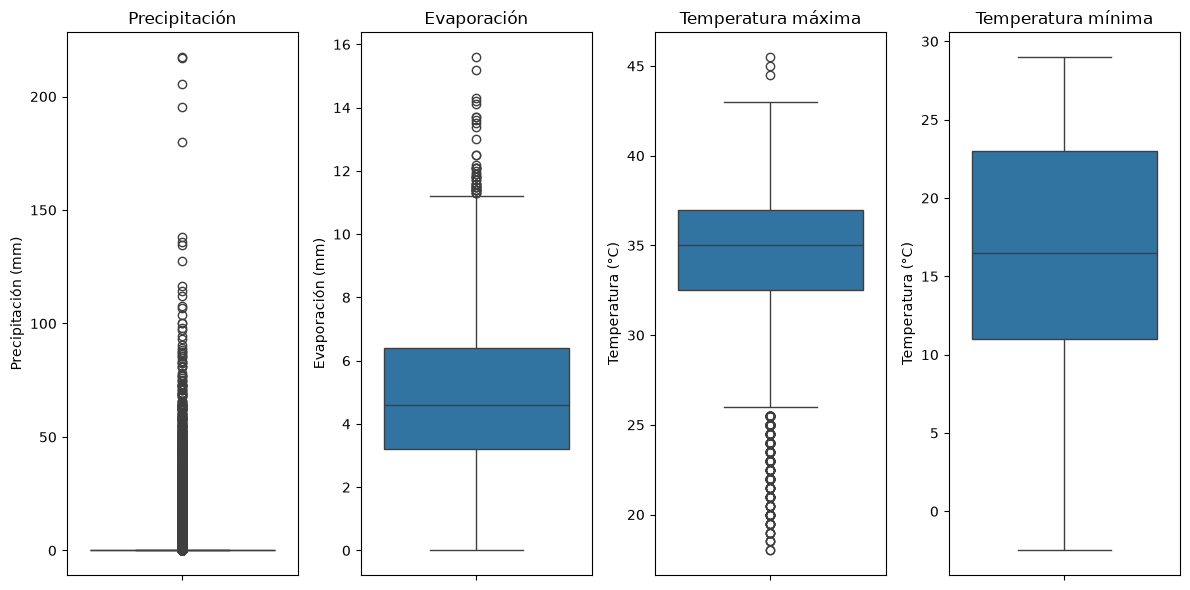

In [ ]:

plt.figure(figsize=(12, 6))


plt.subplot(1, 4, 1)
sns.boxplot(data=df, y="PRECIP")
plt.title("Precipitación")
plt.ylabel("Precipitación (mm)")


plt.subplot(1, 4, 2)
sns.boxplot(data=df, y="EVAP")
plt.title("Evaporación")
plt.ylabel("Evaporación (mm)")


plt.subplot(1, 4, 3)
sns.boxplot(data=df, y="TMAX")
plt.title("Temperatura máxima")
plt.ylabel("Temperatura (°C)")


plt.subplot(1, 4, 4)
sns.boxplot(data=df, y="TMIN")
plt.title("Temperatura mínima")
plt.ylabel("Temperatura (°C)")


plt.tight_layout()


plt.show()

### Conclusión de los diagramas de caja

Los diagramas de caja muestran posibles valores atípicos en las cuatro variables, especialmente en la precipitación, donde aparecen valores muy alejados del resto. La evaporación y las temperaturas también presentan algunos valores fuera de los bigotes. Estos valores no necesariamente son errores, ya que pueden representar condiciones climáticas reales.

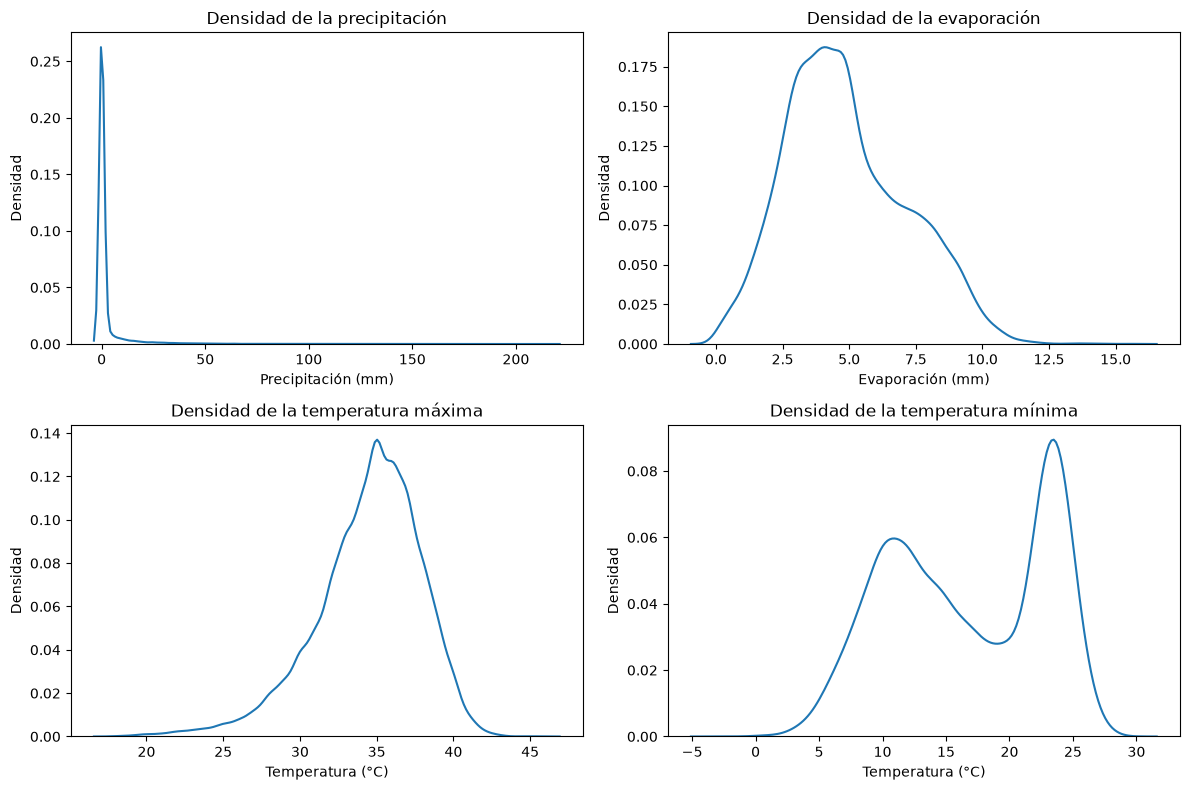

In [ ]:

plt.figure(figsize=(12, 8))


plt.subplot(2, 2, 1)
sns.kdeplot(data=df, x="PRECIP")
plt.title("Densidad de la precipitación")
plt.xlabel("Precipitación (mm)")
plt.ylabel("Densidad")


plt.subplot(2, 2, 2)
sns.kdeplot(data=df, x="EVAP")
plt.title("Densidad de la evaporación")
plt.xlabel("Evaporación (mm)")
plt.ylabel("Densidad")


plt.subplot(2, 2, 3)
sns.kdeplot(data=df, x="TMAX")
plt.title("Densidad de la temperatura máxima")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Densidad")


plt.subplot(2, 2, 4)
sns.kdeplot(data=df, x="TMIN")
plt.title("Densidad de la temperatura mínima")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Densidad")


plt.tight_layout()


plt.show()

### Conclusión de las gráficas de densidad

La precipitación presenta una fuerte concentración cerca de cero y una cola hacia valores altos. La evaporación muestra su mayor densidad entre 3 y 5 mm. La temperatura máxima se concentra alrededor de los 35 °C, mientras que la temperatura mínima presenta dos picos principales, lo que indica dos concentraciones de temperaturas diferentes.

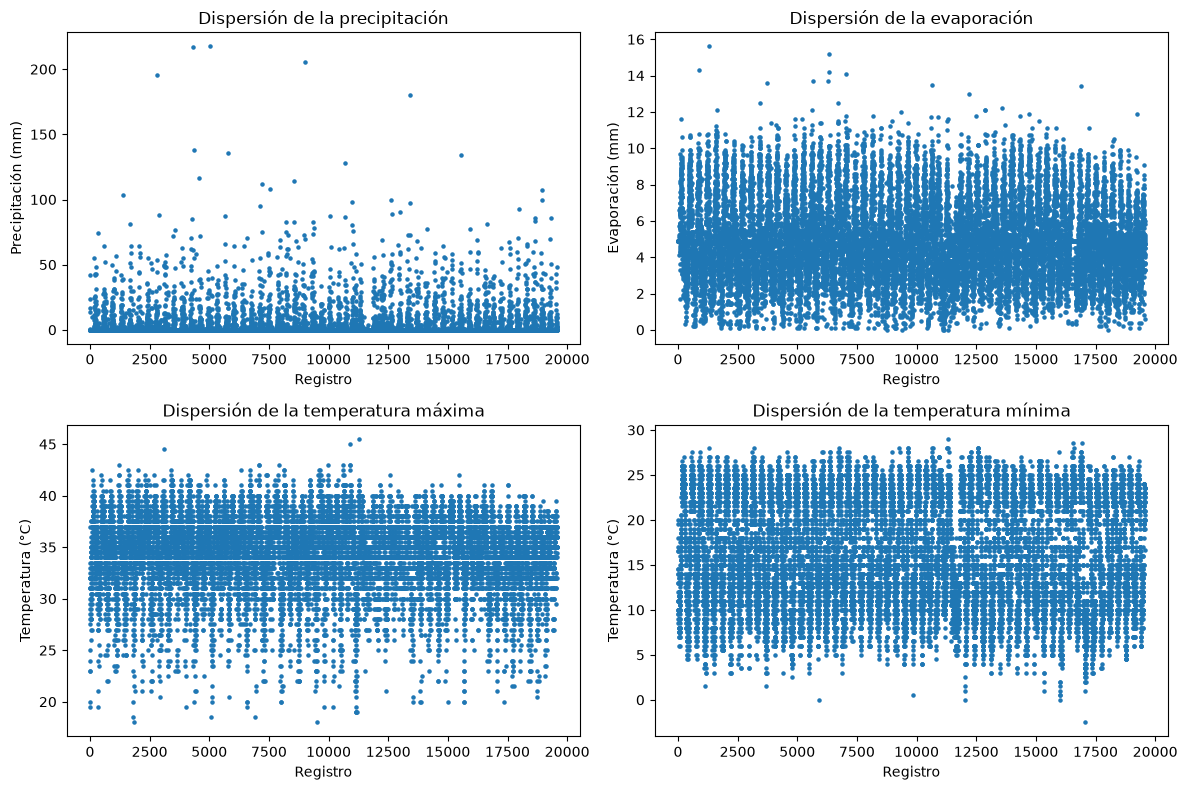

In [ ]:

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.scatter(df.index, df["PRECIP"], s=5)
plt.title("Dispersión de la precipitación")
plt.xlabel("Registro")
plt.ylabel("Precipitación (mm)")


plt.subplot(2, 2, 2)
plt.scatter(df.index, df["EVAP"], s=5)
plt.title("Dispersión de la evaporación")
plt.xlabel("Registro")
plt.ylabel("Evaporación (mm)")


plt.subplot(2, 2, 3)
plt.scatter(df.index, df["TMAX"], s=5)
plt.title("Dispersión de la temperatura máxima")
plt.xlabel("Registro")
plt.ylabel("Temperatura (°C)")


plt.subplot(2, 2, 4)
plt.scatter(df.index, df["TMIN"], s=5)
plt.title("Dispersión de la temperatura mínima")
plt.xlabel("Registro")
plt.ylabel("Temperatura (°C)")


plt.tight_layout()


plt.show()

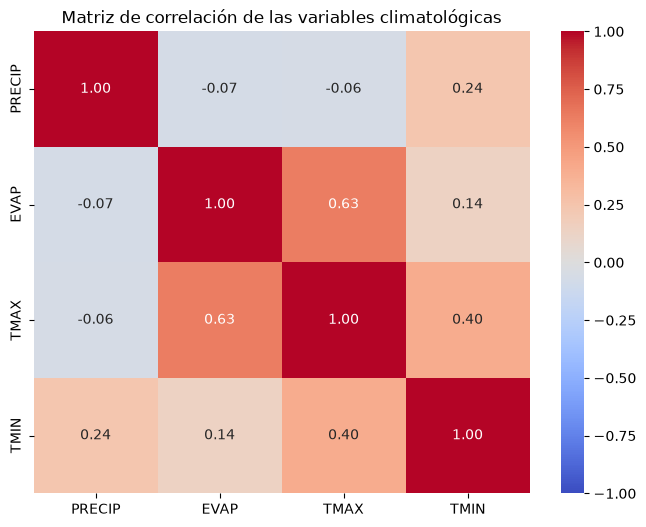

In [ ]:

variables = df[["PRECIP", "EVAP", "TMAX", "TMIN"]]


correlacion = variables.corr()


plt.figure(figsize=(8, 6))


sns.heatmap(correlacion, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")


plt.title("Matriz de correlación de las variables climatológicas")

plt.show()

### Conclusión de la matriz de correlación

En la matriz de correlación se observa que la relación más alta corresponde a **EVAP y TMAX, con 0.63**, lo que representa una correlación positiva fuerte. Esto significa que, cuando aumenta la evaporación, la temperatura máxima tiende a aumentar también.

La relación entre **TMAX y TMIN es de 0.40**, considerada moderada. Entre **PRECIP y TMIN es de 0.24**, una correlación débil. Por otra parte, **EVAP y TMIN presentan 0.14**, una relación muy débil; **PRECIP y EVAP tienen -0.07**, y **PRECIP y TMAX tienen -0.06**, ambas relaciones negativas muy débiles.

Estos resultados indican que la mayoría de las variables no presentan una correlación fuerte entre sí, excepto la evaporación y la temperatura máxima. Por ello, la matriz ayuda a comprender sus relaciones, pero **no demuestra por sí sola que rellenar los datos faltantes con la media aritmética sea el método más adecuado**. Esta decisión también debe considerar la distribución de cada variable. En particular, la precipitación presenta una fuerte asimetría positiva, por lo que utilizar su media podría no representar adecuadamente los días sin lluvia o con poca precipitación.